# 02 · Exploratory data analysis

**Goal:** see how wellbeing relates to social-media habits *before* modeling, and test whether the patterns are statistically real.
Previous: [01 Data & cleaning](01_data_understanding_and_cleaning.ipynb) · Next: [03 Modeling](03_modeling.ipynb)

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from wellbeing.config import Settings
from wellbeing.data import CLASSES, TARGET, add_target, clean, feature_frame, load_raw

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
PALETTE = {"Low": "#d1495b", "Medium": "#edae49", "High": "#2e86ab"}  # one colour per wellbeing group, reused everywhere

# Settings points at the CSV and names every column; the notebooks run from the notebooks/ folder
s = Settings(data_file=Path("../data/social_media_addiction_mental_wellbeing.csv"))
from scipy import stats

df, _ = clean(load_raw(s), s)
df, cuts = add_target(df, s)
df["hours_band"] = pd.cut(df[s.hours_column], [0, 2, 4, 6, 8, 100], labels=["< 2 h", "2-4 h", "4-6 h", "6-8 h", "8+ h"], right=False)

## 1. The wellbeing score and daily hours

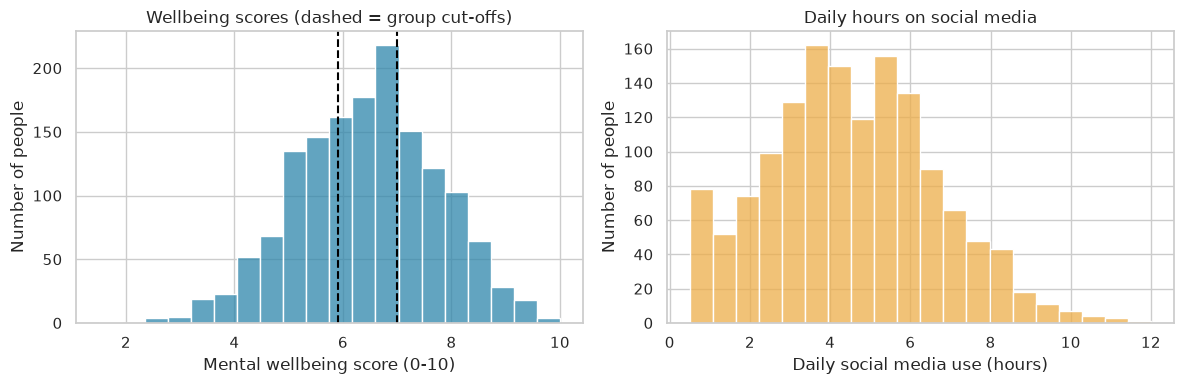

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df[s.score_column], bins=20, color="#2e86ab", ax=axes[0])
for c in (cuts["low_below"], cuts["high_from"]):
    axes[0].axvline(c, color="black", ls="--")
axes[0].set_xlabel("Mental wellbeing score (0-10)")
axes[0].set_ylabel("Number of people")
axes[0].set_title("Wellbeing scores (dashed = group cut-offs)")

sns.histplot(df[s.hours_column], bins=20, color="#edae49", ax=axes[1])
axes[1].set_xlabel("Daily social media use (hours)")
axes[1].set_ylabel("Number of people")
axes[1].set_title("Daily hours on social media")
plt.tight_layout()
plt.show()

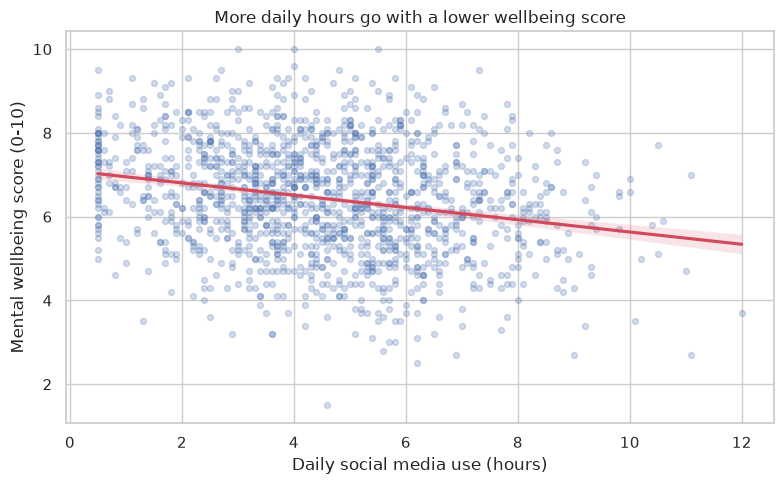

In [3]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.regplot(data=df, x=s.hours_column, y=s.score_column, scatter_kws={"alpha": 0.25, "s": 18}, line_kws={"color": "#d1495b"}, ax=ax)
ax.set_xlabel("Daily social media use (hours)")
ax.set_ylabel("Mental wellbeing score (0-10)")
ax.set_title("More daily hours go with a lower wellbeing score")
plt.tight_layout()
plt.show()

### Statistical test
Spearman's rank correlation measures whether two things move together (-1 to +1) without assuming a straight line. A p-value below 0.05 means the pattern is unlikely to be chance.

In [4]:
ok = df[s.hours_column].notna()
rho, p = stats.spearmanr(df.loc[ok, s.hours_column], df.loc[ok, s.score_column])
print(f"Spearman rho = {rho:.3f}, p = {p:.2g}, n = {ok.sum()}")

Spearman rho = -0.229, p = 1.1e-18, n = 1444


**Interpretation.** ρ is negative and highly significant (p < 0.001): people who use social media more hours a day tend to have lower wellbeing. The size is *modest* (|ρ| ≈ 0.23), so hours alone are far from the whole story.

## 2. Share of Low / Medium / High wellbeing by hours of use

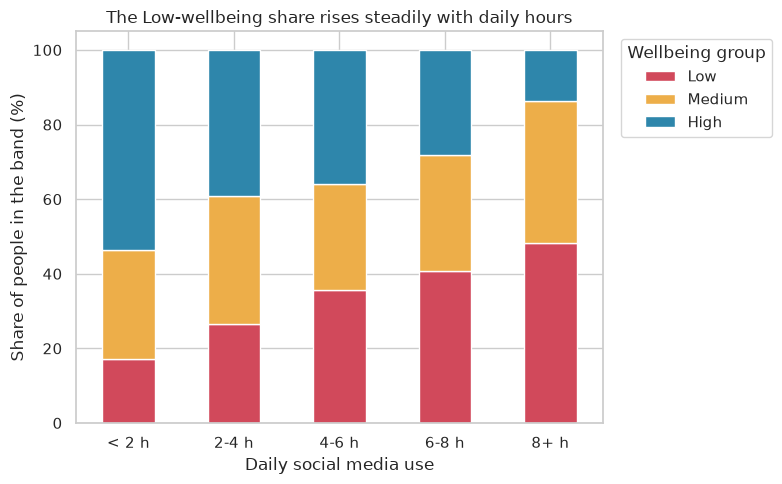

wellbeing_class,Low,Medium,High
hours_band,,,
< 2 h,17.1,29.4,53.5
2-4 h,26.4,34.4,39.2
4-6 h,35.6,28.6,35.8
6-8 h,40.7,31.2,28.1
8+ h,48.3,37.9,13.8


In [5]:
share = pd.crosstab(df["hours_band"], df[TARGET], normalize="index").reindex(columns=CLASSES) * 100

ax = share.plot(kind="bar", stacked=True, color=[PALETTE[c] for c in CLASSES], figsize=(8, 5))
ax.set_xlabel("Daily social media use")
ax.set_ylabel("Share of people in the band (%)")
ax.set_title("The Low-wellbeing share rises steadily with daily hours")
ax.legend(title="Wellbeing group", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()
share.round(1)

## 3. Habits: late-night use, checking after waking, failing to cut back

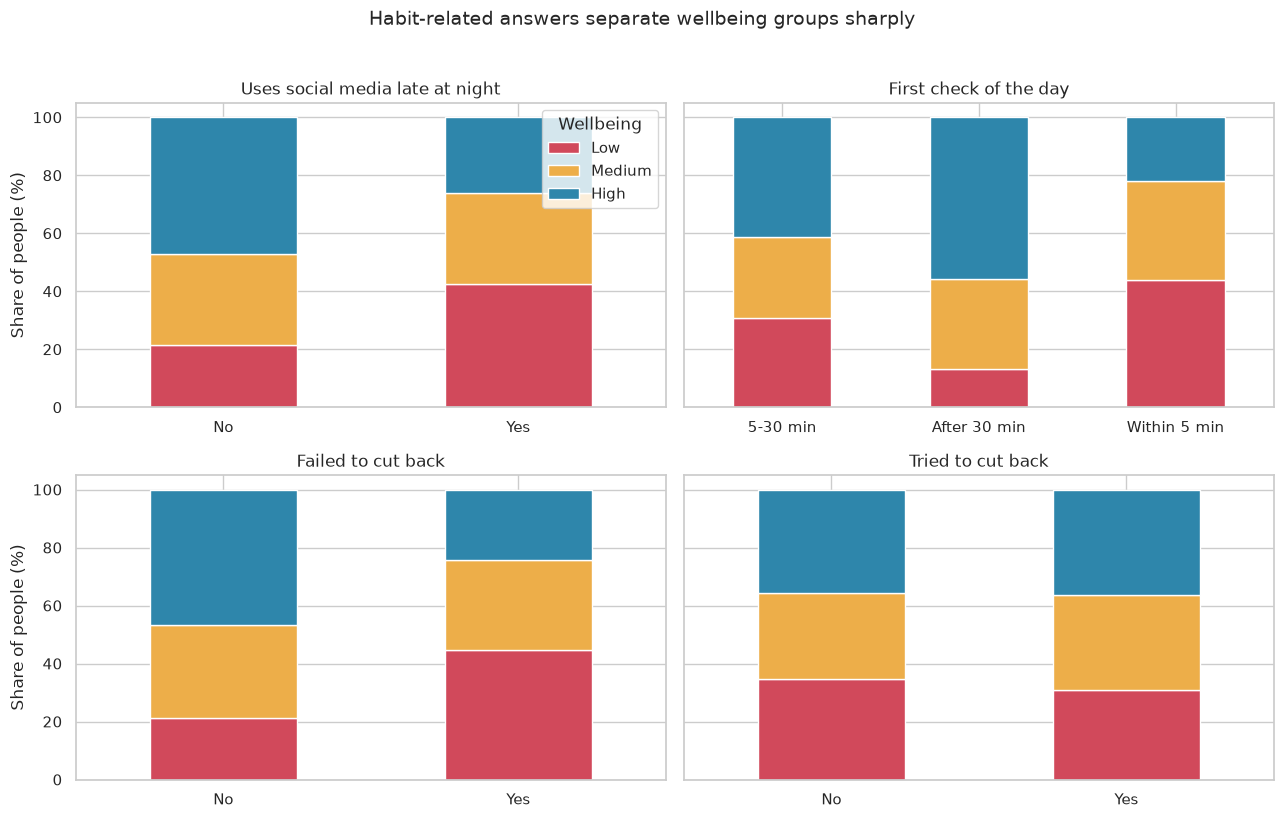

In [6]:
habits = ["late_night_usage", "first_check_morning", "failed_to_cut_back", "tried_to_cut_back"]
titles = ["Uses social media late at night", "First check of the day", "Failed to cut back", "Tried to cut back"]

fig, axes = plt.subplots(2, 2, figsize=(13, 8), sharey=True)
for ax, col, title in zip(axes.ravel(), habits, titles):
    sub = df.dropna(subset=[col])
    t = pd.crosstab(sub[col], sub[TARGET], normalize="index").reindex(columns=CLASSES) * 100
    t.plot(kind="bar", stacked=True, color=[PALETTE[c] for c in CLASSES], ax=ax, legend=False)
    ax.set_title(title)
    ax.set_xlabel("")
    ax.set_ylabel("Share of people (%)")
    ax.tick_params(axis="x", rotation=0)
axes[0, 0].legend(title="Wellbeing", loc="upper right")
fig.suptitle("Habit-related answers separate wellbeing groups sharply", y=1.02, fontsize=14)
plt.tight_layout()
plt.show()

### Statistical test: are habits and wellbeing group independent?
A chi-square test asks whether the group mix differs more between answers than chance would explain.

In [7]:
rows = []
for col in habits + ["gender", "occupation", "relationship_status", "primary_platform"]:
    sub = df.dropna(subset=[col])
    chi2, p, dof, _ = stats.chi2_contingency(pd.crosstab(sub[col], sub[TARGET]))
    rows.append({"variable": col, "chi2": round(chi2, 1), "p_value": p, "significant (p<0.05)": p < 0.05})
pd.DataFrame(rows).sort_values("p_value")

,variable,chi2,p_value,significant (p<0.05)
1,first_check_morning,149.7,2.415776e-31,True
2,failed_to_cut_back,112.5,3.764210e-25,True
0,late_night_usage,94.2,3.489728e-21,True
7,primary_platform,34.7,1.385583e-04,True
3,tried_to_cut_back,2.3,3.115024e-01,False
6,relationship_status,4.1,3.985782e-01,False
4,gender,2.2,6.987859e-01,False
5,occupation,1.8,9.350318e-01,False


**Interpretation.** Three habit variables are highly significant: checking within minutes of waking, failing to cut back, and late-night use. Primary platform is also significant but far weaker (chi² 35 vs 94-150). Merely *trying* to cut back, gender, occupation and relationship status show no evidence of a link (p > 0.3). So *how* people use social media says more than *who* they are.

## 4. Demographics and platform

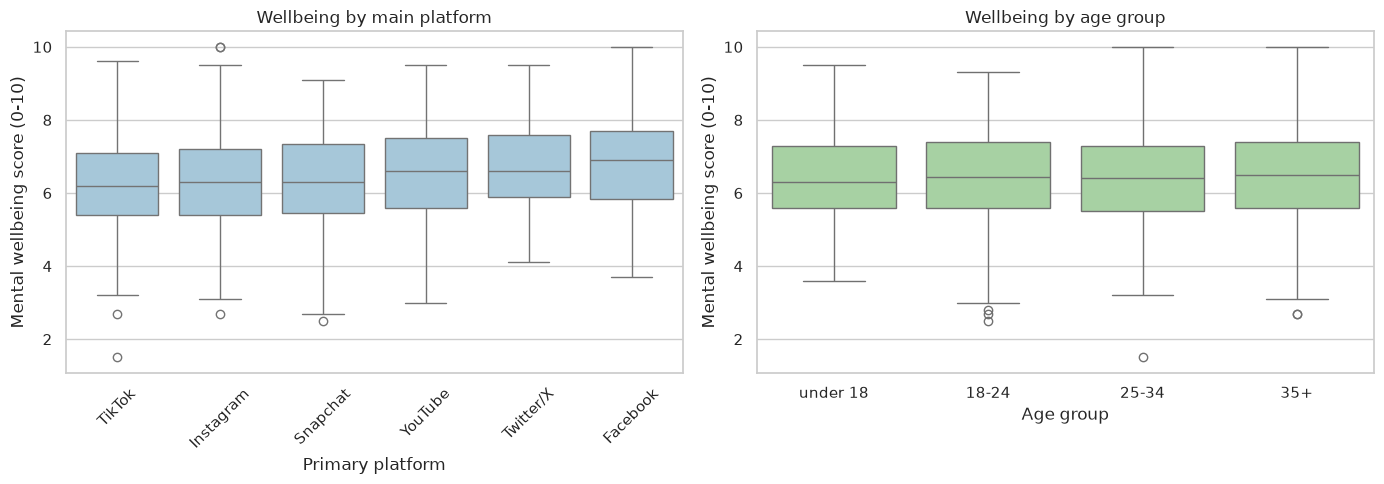

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
order = df.groupby("primary_platform")[s.score_column].mean().sort_values().index
sns.boxplot(data=df, x="primary_platform", y=s.score_column, order=order, color="#9ecae1", ax=axes[0])
axes[0].set_xlabel("Primary platform")
axes[0].set_ylabel("Mental wellbeing score (0-10)")
axes[0].set_title("Wellbeing by main platform")
axes[0].tick_params(axis="x", rotation=45)

df["age_group"] = pd.cut(df[s.age_column], [0, 17, 24, 34, 200], labels=["under 18", "18-24", "25-34", "35+"])
sns.boxplot(data=df, x="age_group", y=s.score_column, color="#a1d99b", ax=axes[1])
axes[1].set_xlabel("Age group")
axes[1].set_ylabel("Mental wellbeing score (0-10)")
axes[1].set_title("Wellbeing by age group")
plt.tight_layout()
plt.show()

Platforms differ modestly (the Low-group share runs from about 24% on Twitter/X and Facebook to 38% on Instagram) and age groups barely differ at all (mean scores within 0.1 point).

## 5. Which numeric measures move with wellbeing?
The psychological measures (anxiety, depression, ...) are marked because they describe mental state itself and are therefore **not** used in the main model.

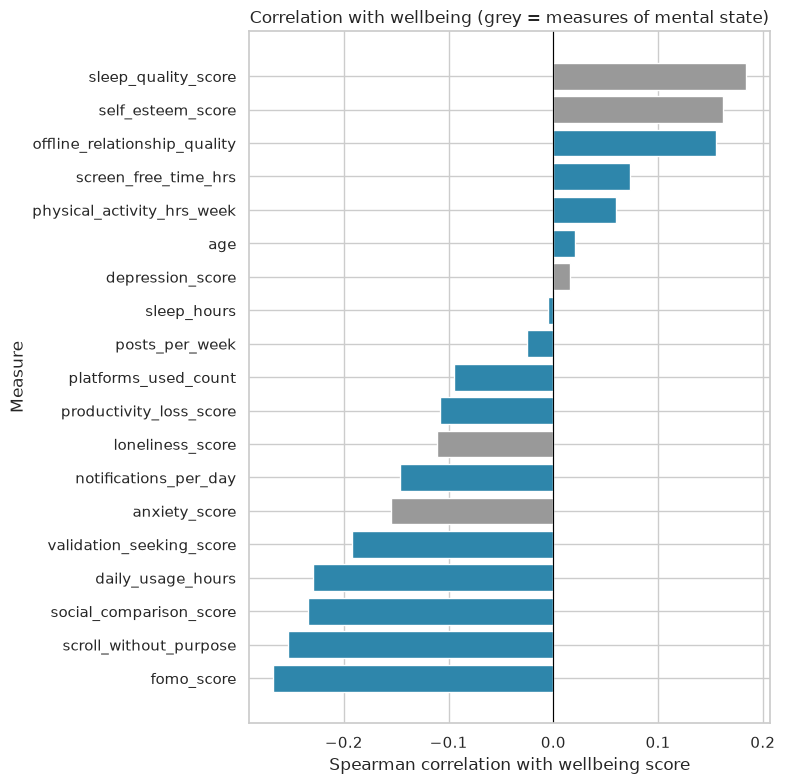

In [9]:
mediators = set(s.mediator_columns)
num = [c for c in df.select_dtypes("number").columns if c not in {*s.id_columns, s.score_column}]
corr = df[num + [s.score_column]].corr(method="spearman")[s.score_column].drop(s.score_column).sort_values()

fig, ax = plt.subplots(figsize=(8, 8))
colors = ["#999999" if c in mediators else "#2e86ab" for c in corr.index]
ax.barh(corr.index, corr.values, color=colors)
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("Spearman correlation with wellbeing score")
ax.set_ylabel("Measure")
ax.set_title("Correlation with wellbeing (grey = measures of mental state)")
plt.tight_layout()
plt.show()

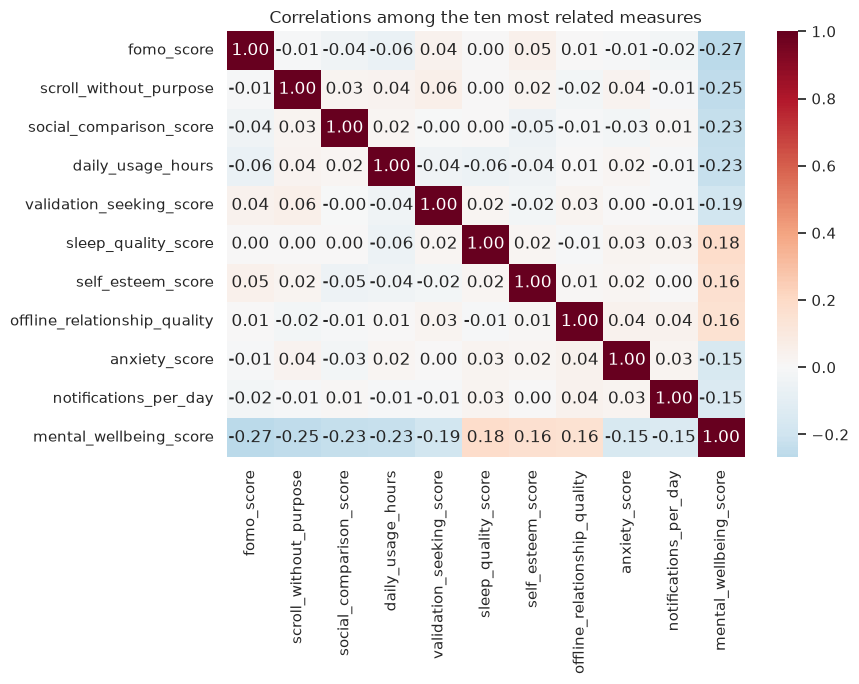

In [10]:
top = corr.abs().sort_values(ascending=False).head(10).index
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(df[list(top) + [s.score_column]].corr(method="spearman"), annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax)
ax.set_title("Correlations among the ten most related measures")
plt.tight_layout()
plt.show()

## Takeaways from the exploration
1. More daily hours go with lower wellbeing, gradually and not as a sudden cliff (ρ ≈ -0.23).
2. Three habits (late-night use, failing to cut back, checking within minutes of waking) separate groups strongly; merely trying to cut back does not.
3. Demographics (age, gender, occupation) matter little; platform matters modestly.
4. Several measures are tangled together, so we need a model that weighs them jointly → [03 Modeling](03_modeling.ipynb).